In [17]:
# === ON vs OFF analysis on window features ===
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
from scipy.stats import shapiro, ttest_ind, mannwhitneyu, wilcoxon
# ==== IMPORTS ====
import pandas as pd, numpy as np
import seaborn as sns, matplotlib.pyplot as plt
from scipy.stats import kruskal, spearmanr

# Mixed effects (optional)
import statsmodels.formula.api as smf


In [7]:
win_task1 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/windows_task1.csv")
win_task2 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/windows_task2.csv")
win_task3 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/windows_task3.csv")


Running ON/OFF analysis → Task 1.x


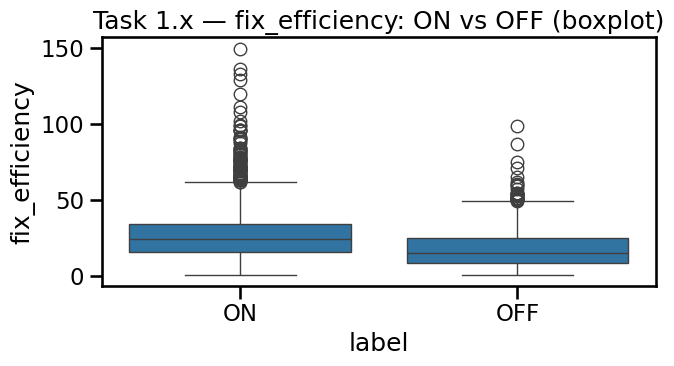

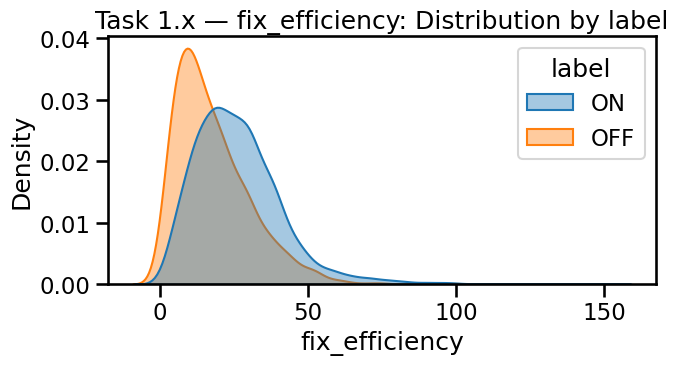

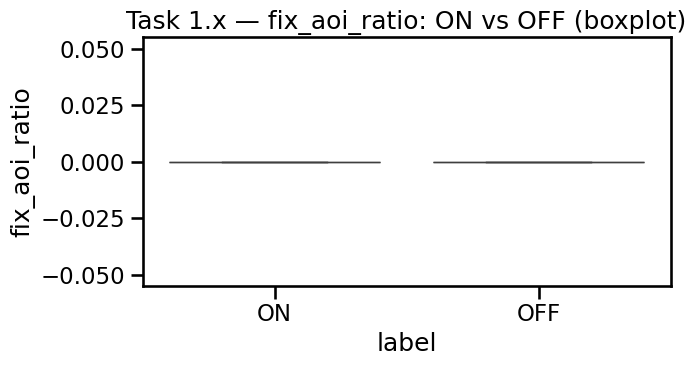

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_7277/2854102243.py:63: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=df, x=f, hue="label", common_norm=False, fill=True, alpha=0.4)


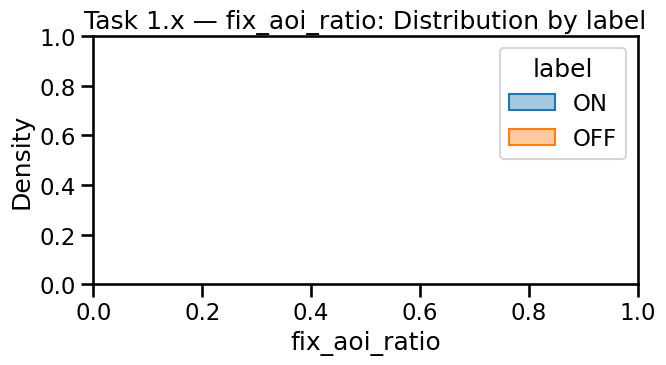

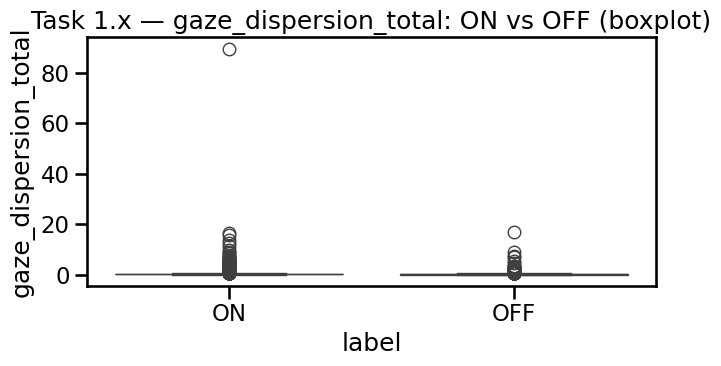

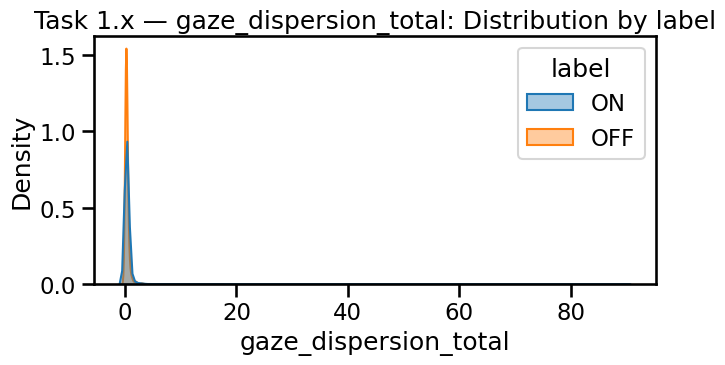

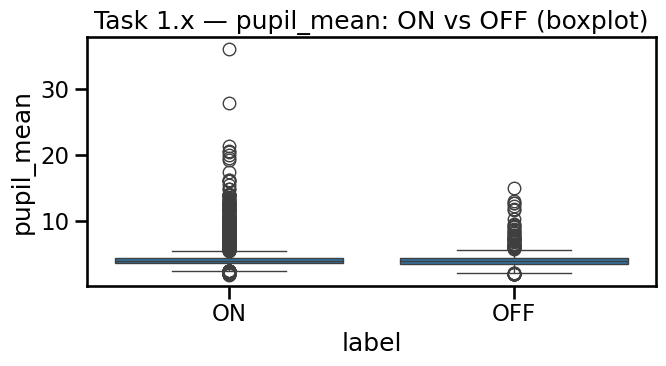

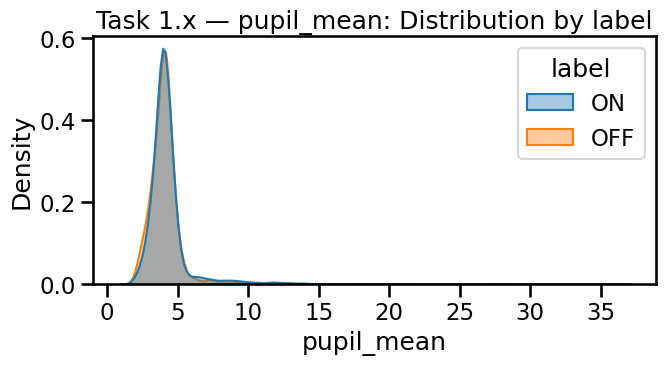

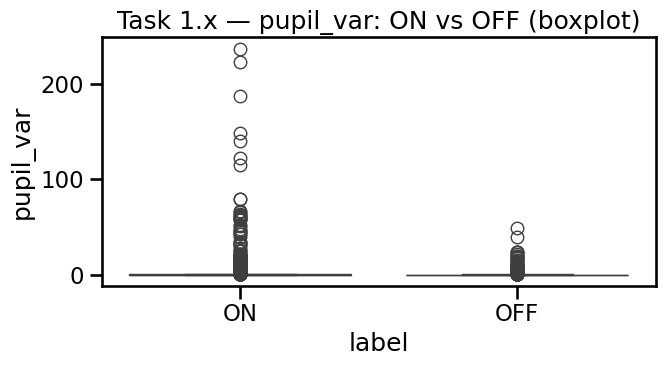

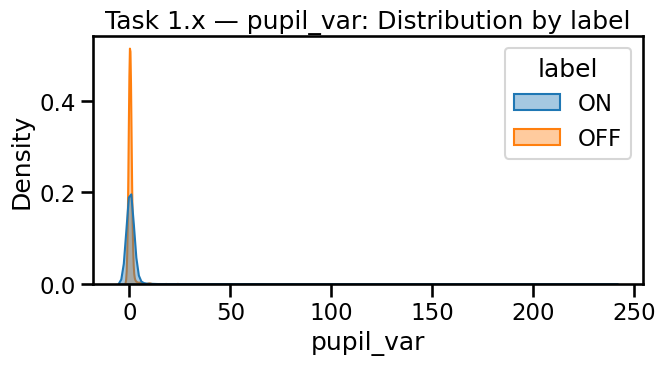

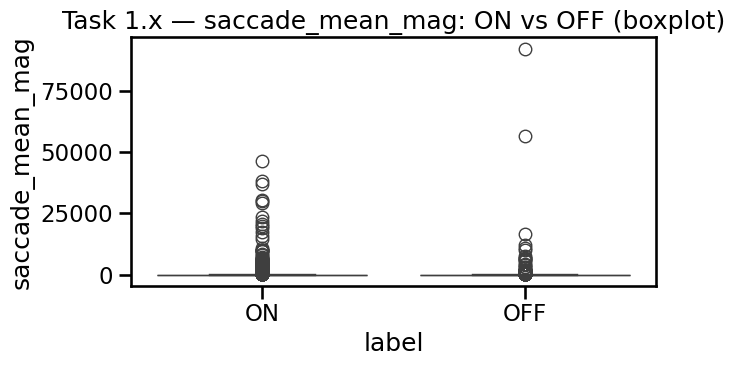

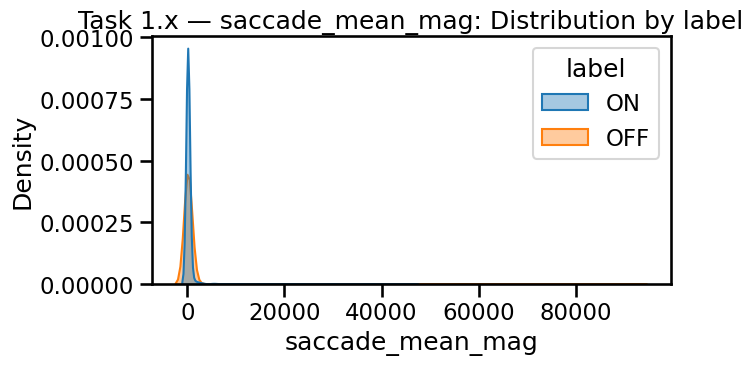

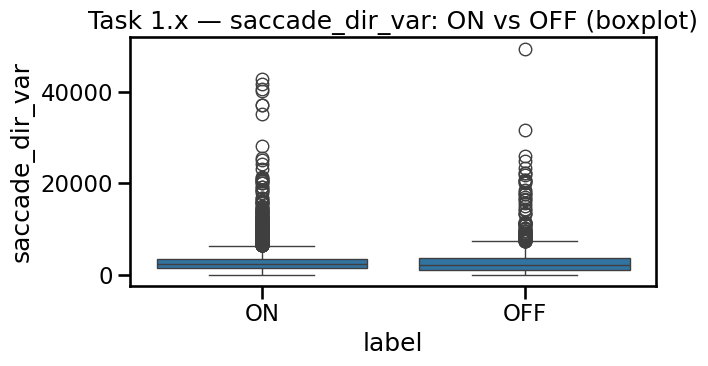

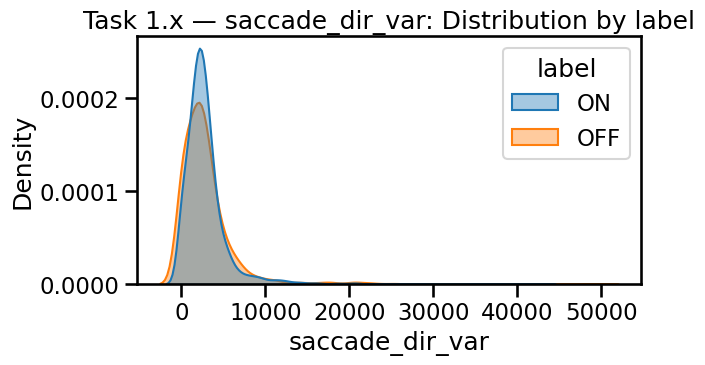

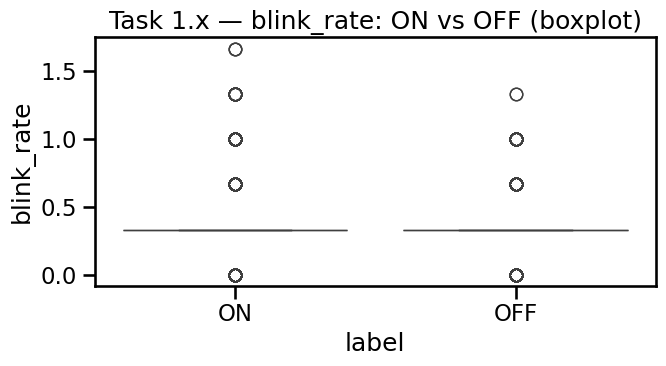

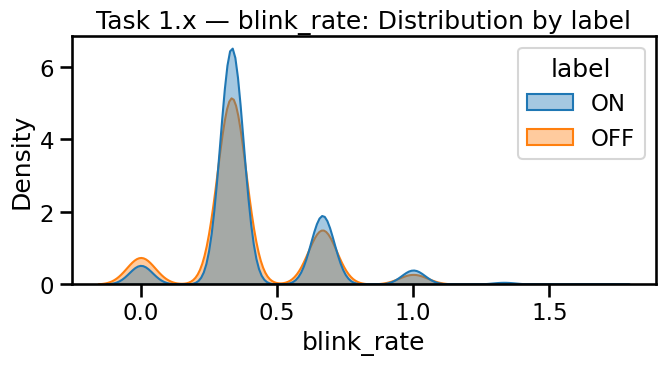

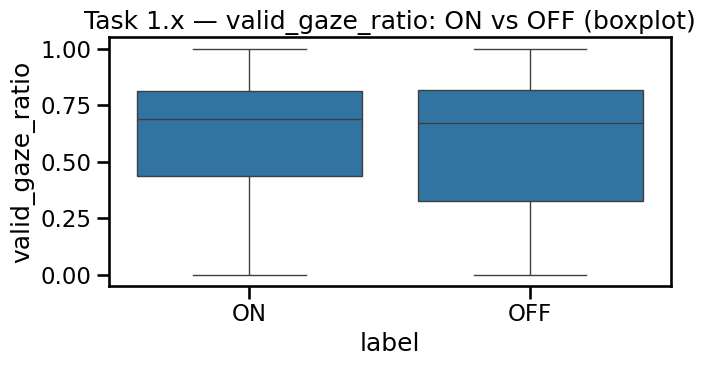

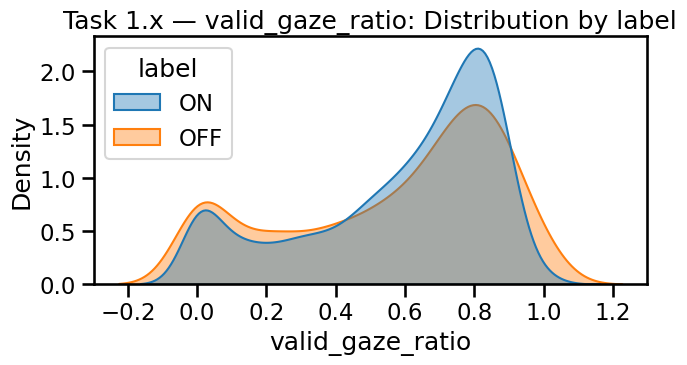

/opt/anaconda3/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)



=== Task 1.x: Global ON vs OFF summary ===
              feature     mean_ON    mean_OFF      p_value  effect_size                     test  n_ON  n_OFF
       fix_efficiency   26.441235   17.978997 8.191413e-71    -0.309732 Mann-Whitney (Cliff's δ)  3210   1035
gaze_dispersion_total    0.400888    0.313066 1.421010e-13    -0.149964 Mann-Whitney (Cliff's δ)  3211   1040
            pupil_var    1.332935    0.643364 1.954009e-06    -0.034427 Mann-Whitney (Cliff's δ)  3431   1198
     saccade_mean_mag  299.916880  336.094488 2.037450e-05    -0.050973 Mann-Whitney (Cliff's δ)  3242   1083
           blink_rate    0.416302    0.391486 1.839983e-03     0.000000 Mann-Whitney (Cliff's δ)  3431   1198
           pupil_mean    4.300387    4.044047 1.093202e-02    -0.049882 Mann-Whitney (Cliff's δ)  3385   1167
      saccade_dir_var 2879.937336 2897.654426 1.384421e-02     0.023811 Mann-Whitney (Cliff's δ)  3431   1198
     valid_gaze_ratio    0.590670    0.567080 2.978623e-01     0.019128 Mann

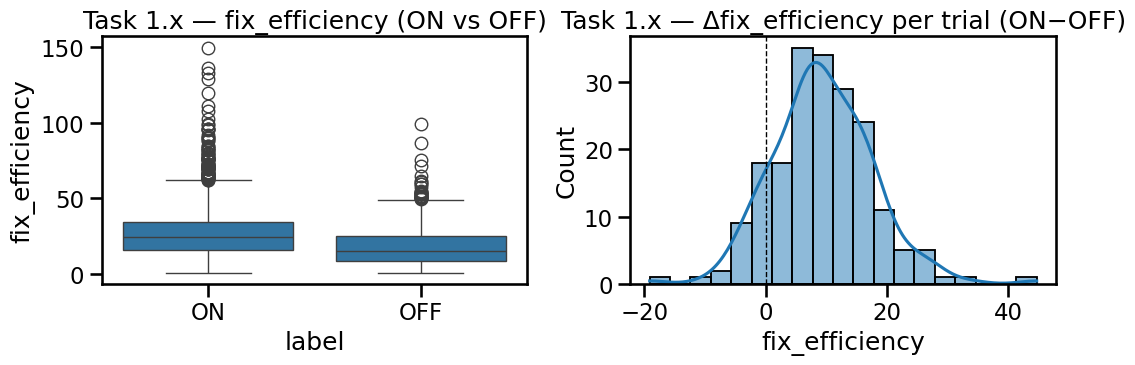

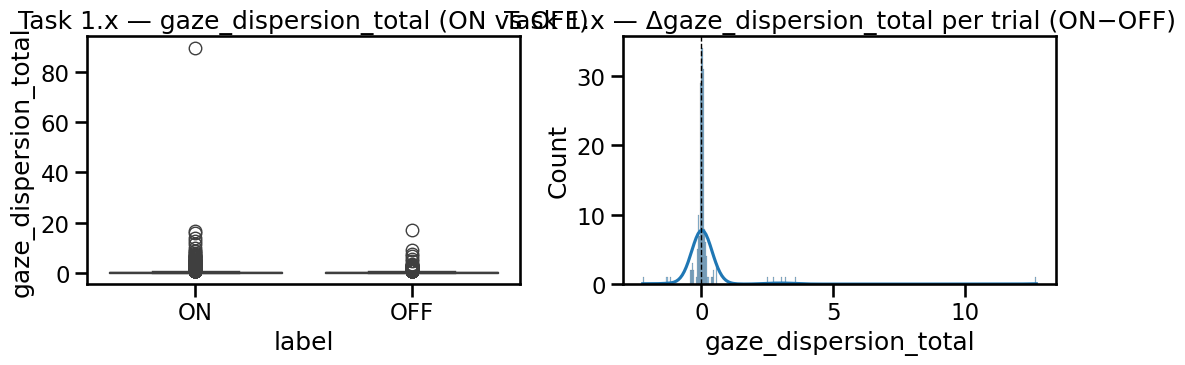

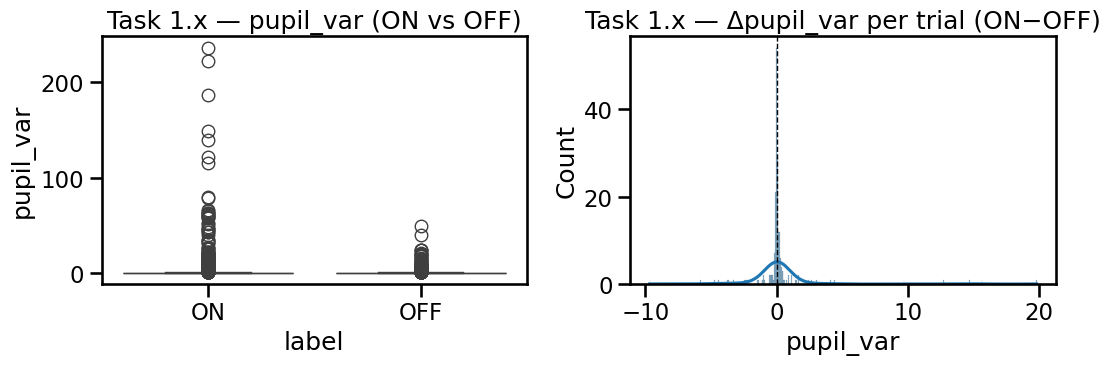


Running ON/OFF analysis → Task 2.x


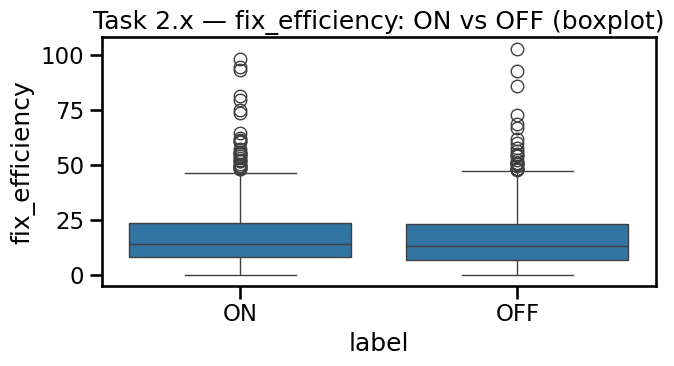

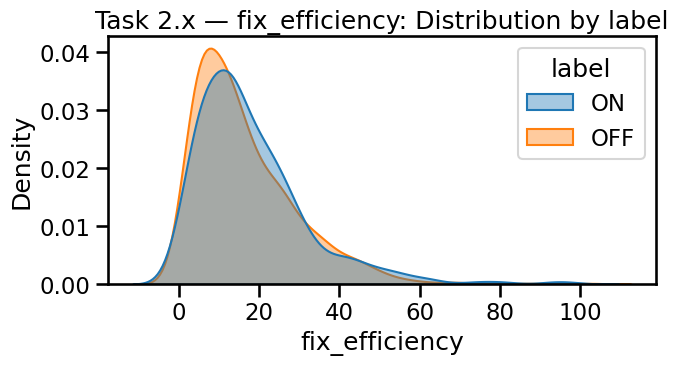

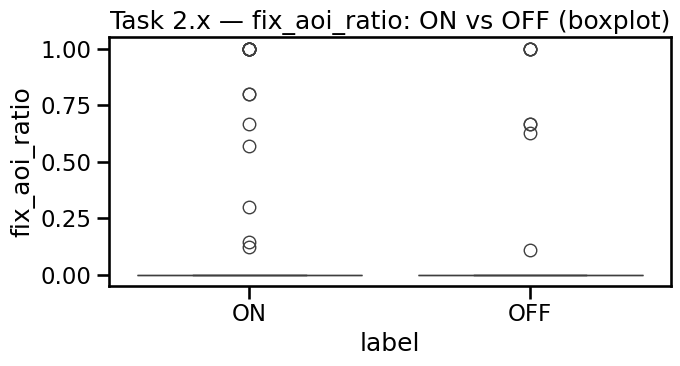

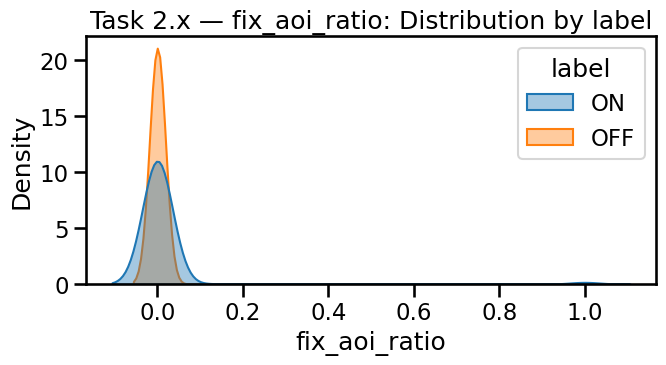

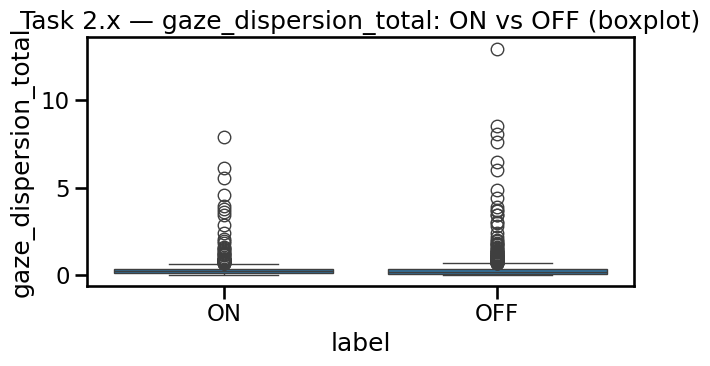

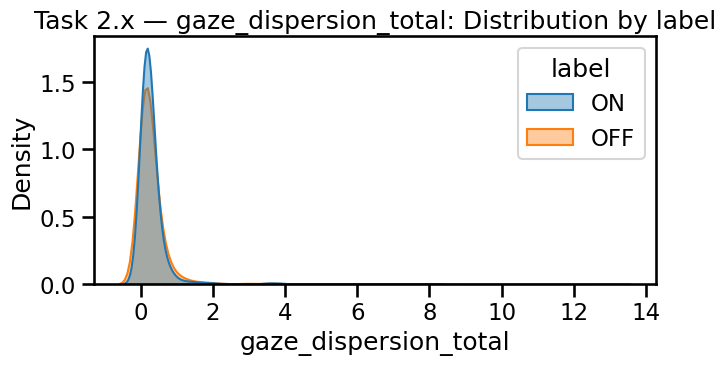

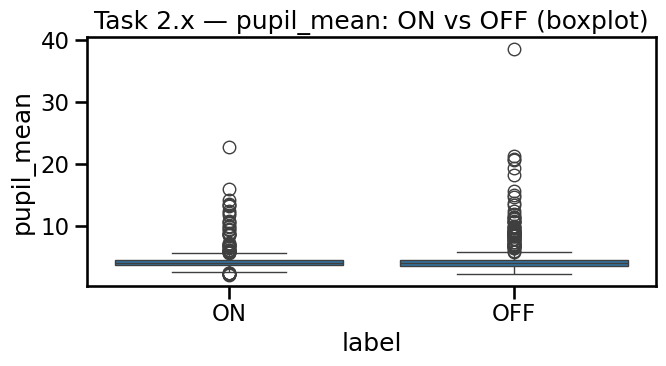

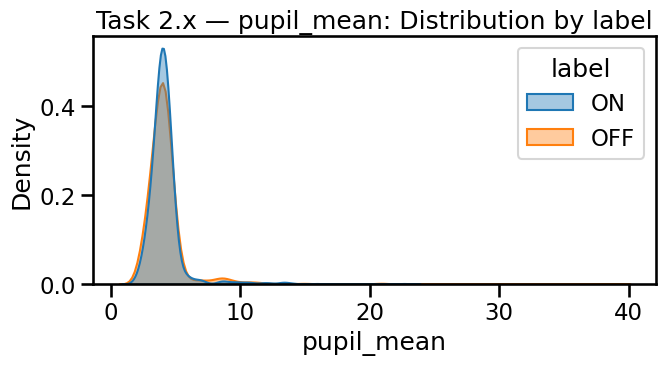

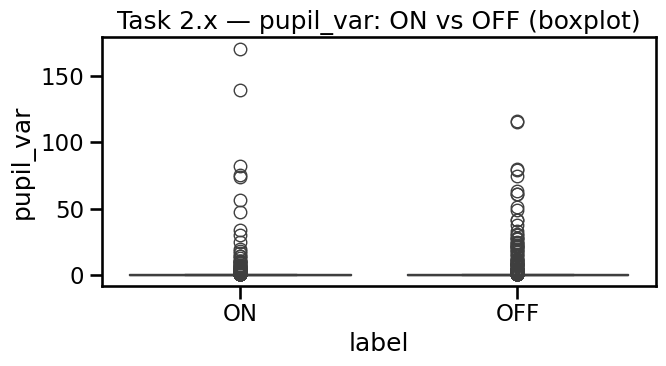

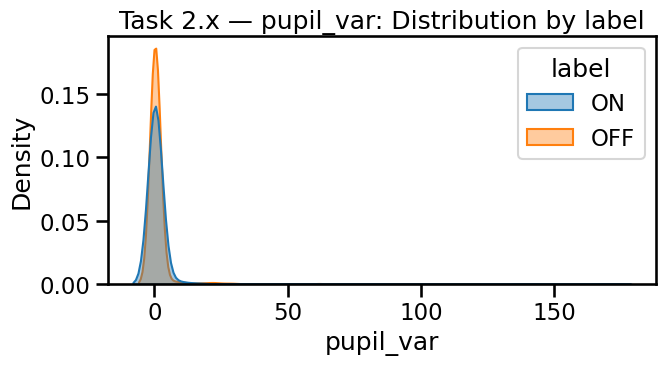

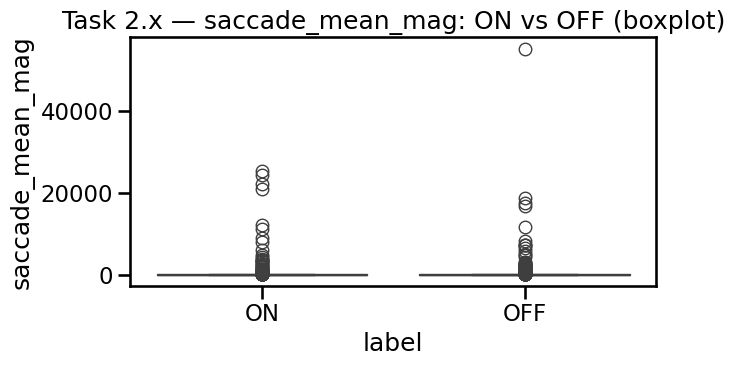

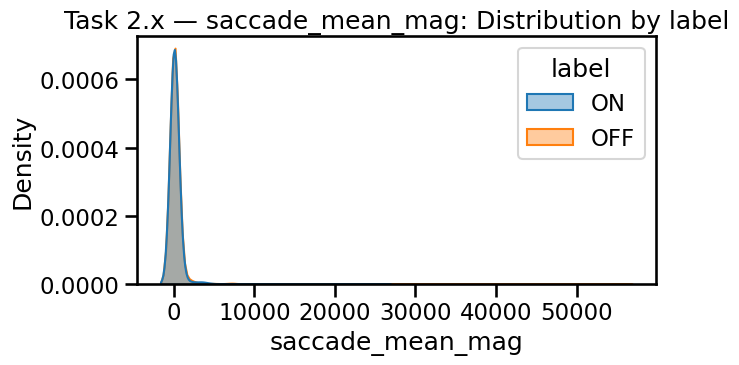

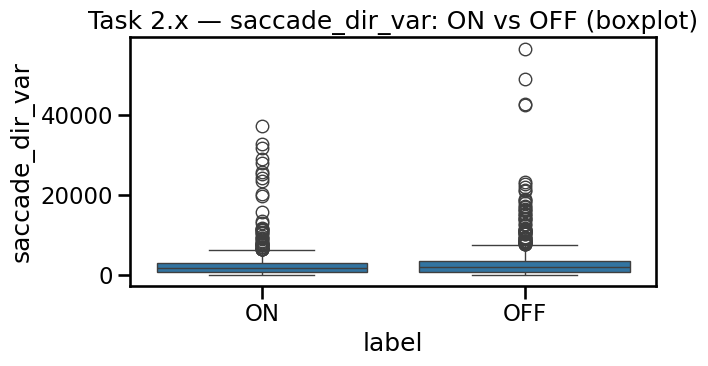

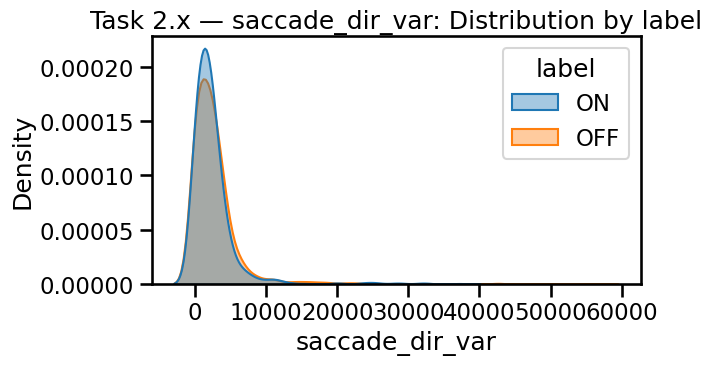

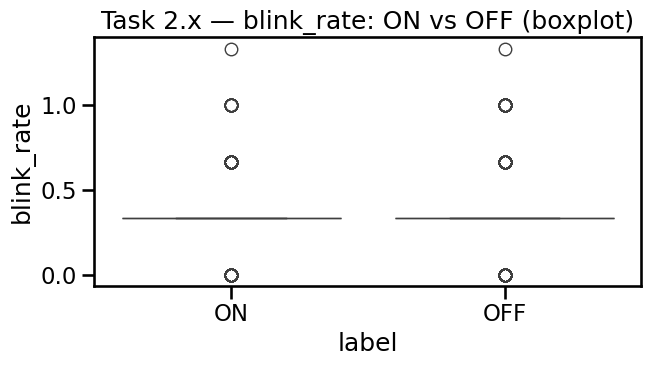

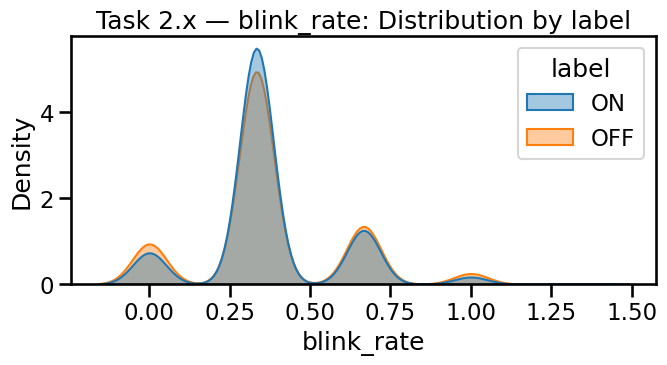

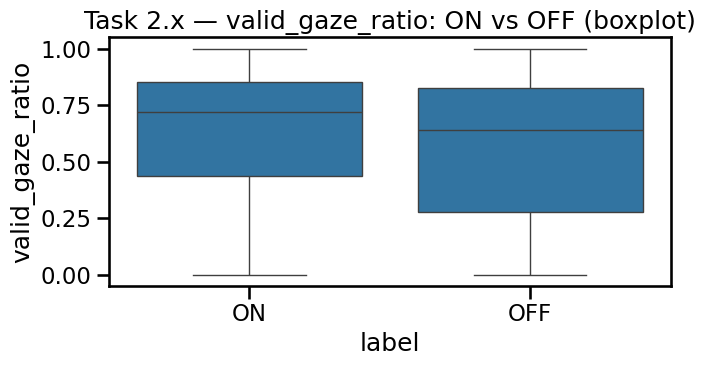

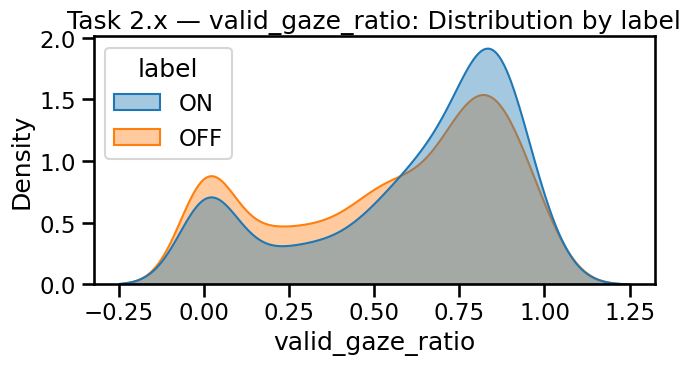


=== Task 2.x: Global ON vs OFF summary ===
              feature     mean_ON    mean_OFF  p_value  effect_size                     test  n_ON  n_OFF
     valid_gaze_ratio    0.608899    0.551927 0.000148    -0.066934 Mann-Whitney (Cliff's δ)   745   1158
        fix_aoi_ratio    0.018969    0.006336 0.008674     0.000013 Mann-Whitney (Cliff's δ)   654    958
       fix_efficiency   18.100683   16.589070 0.017592    -0.071232 Mann-Whitney (Cliff's δ)   654    958
gaze_dispersion_total    0.309014    0.336542 0.081427    -0.051462 Mann-Whitney (Cliff's δ)   653    962
      saccade_dir_var 2483.532901 2677.951463 0.147875     0.086382 Mann-Whitney (Cliff's δ)   745   1158
            pupil_var    1.492097    1.531529 0.186184     0.071588 Mann-Whitney (Cliff's δ)   745   1158
           pupil_mean    4.187487    4.248969 0.277935    -0.029930 Mann-Whitney (Cliff's δ)   723   1113
     saccade_mean_mag  342.398041  296.346884 0.404190     0.048567 Mann-Whitney (Cliff's δ)   674   1013
  

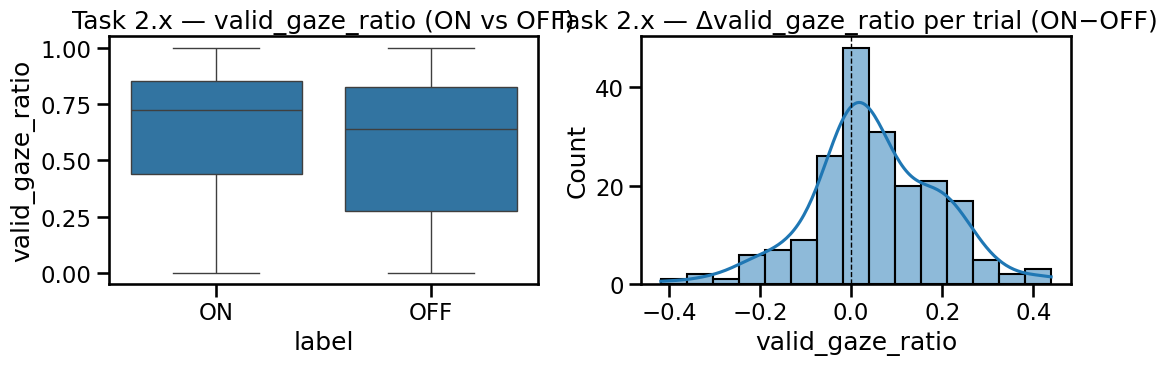

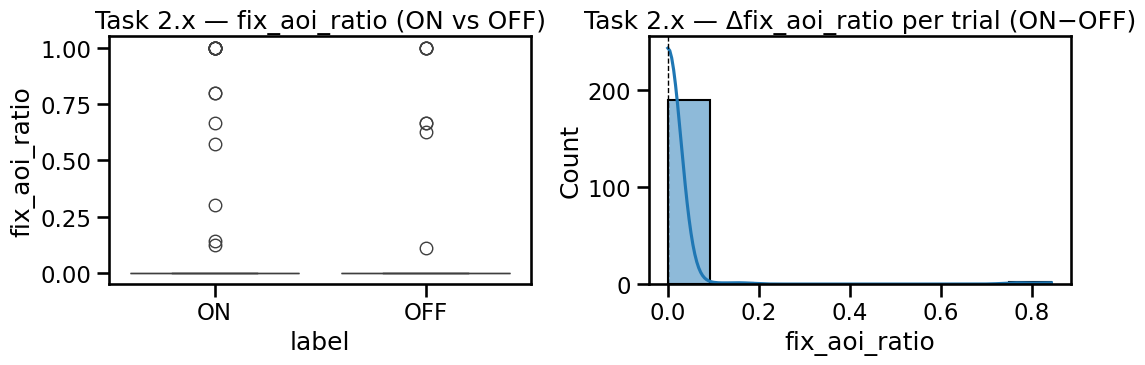

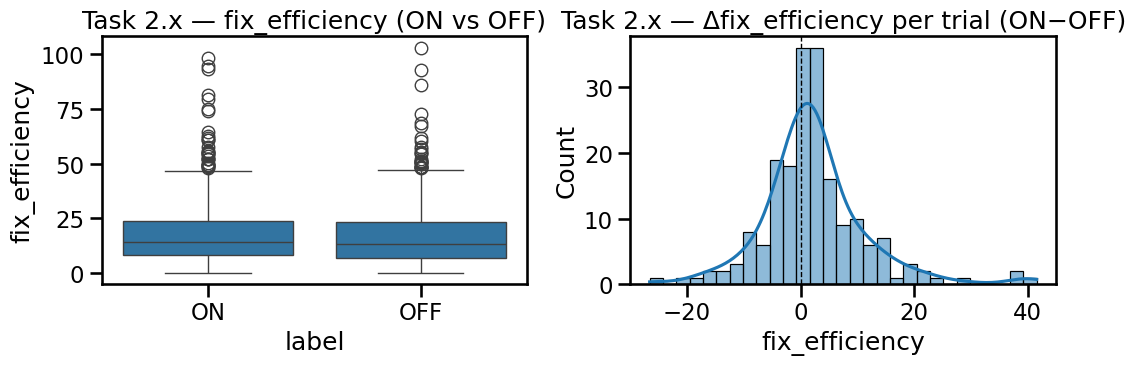


Running ON/OFF analysis → Task 3.x


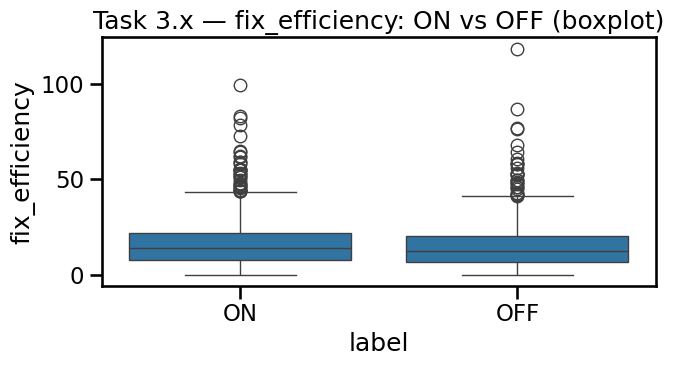

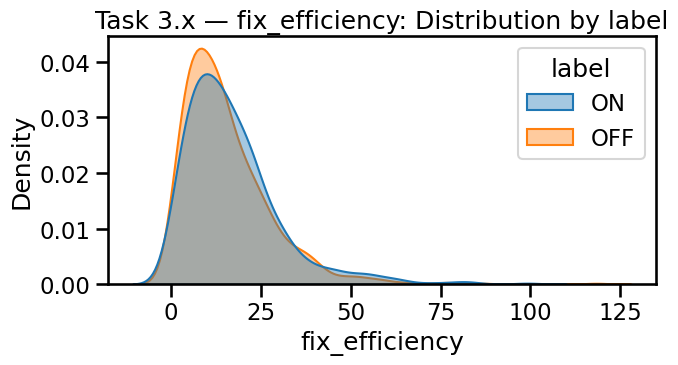

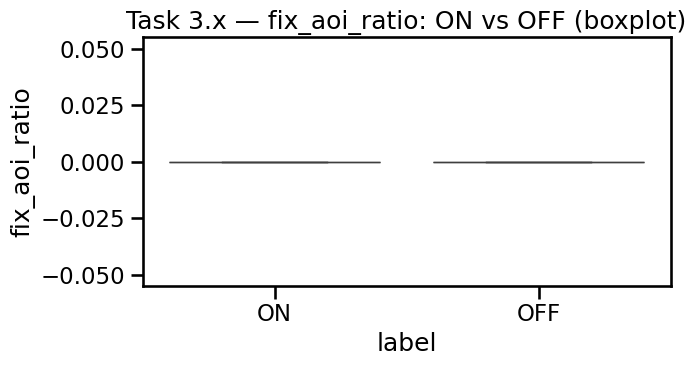

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_7277/2854102243.py:63: UserWarning: Dataset has 0 variance; skipping density estimate. Pass `warn_singular=False` to disable this warning.
  sns.kdeplot(data=df, x=f, hue="label", common_norm=False, fill=True, alpha=0.4)


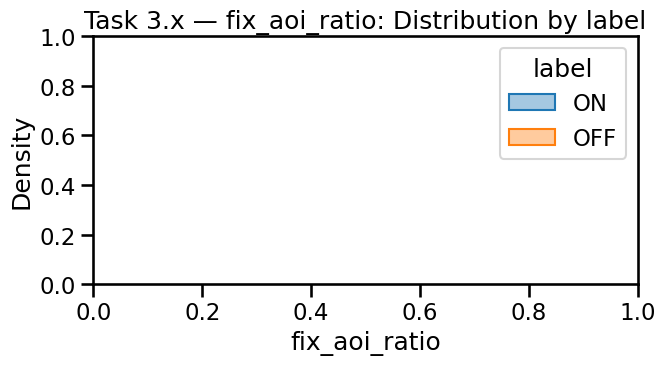

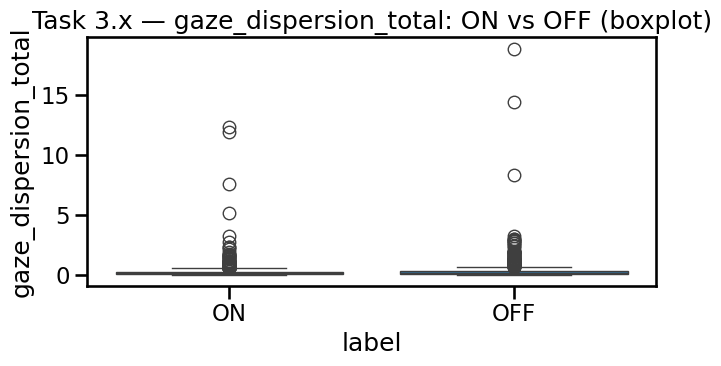

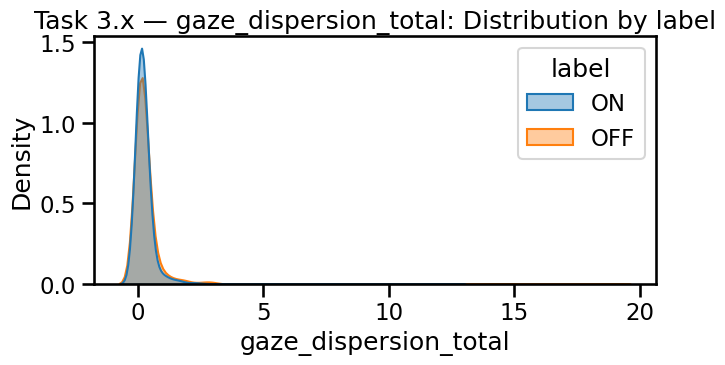

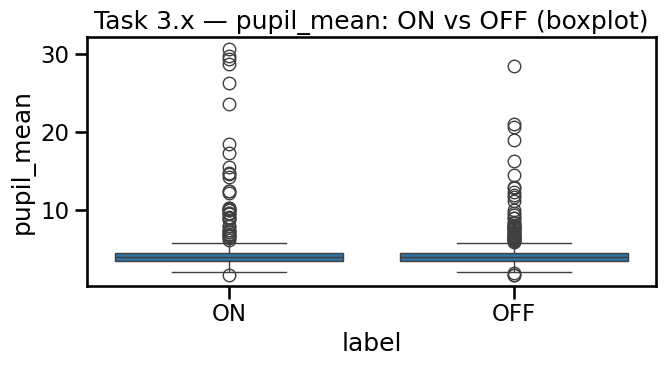

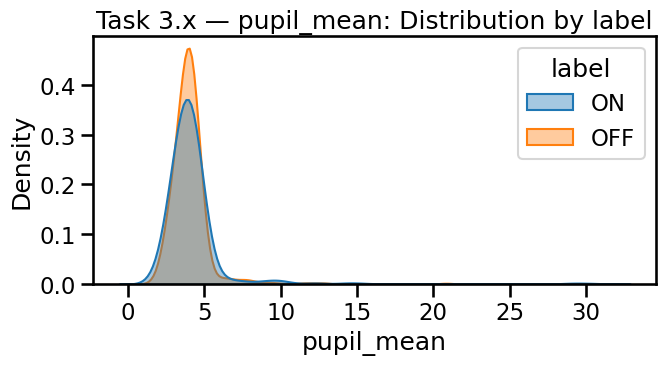

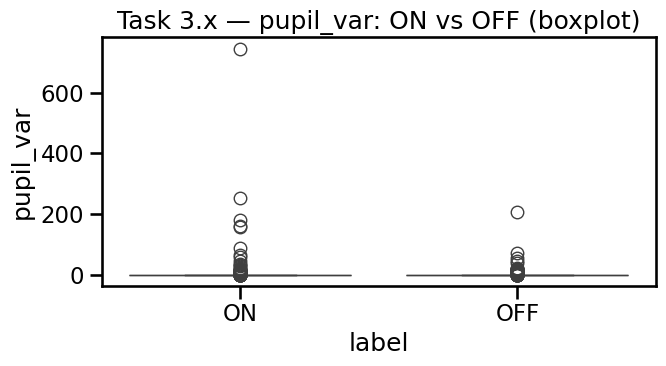

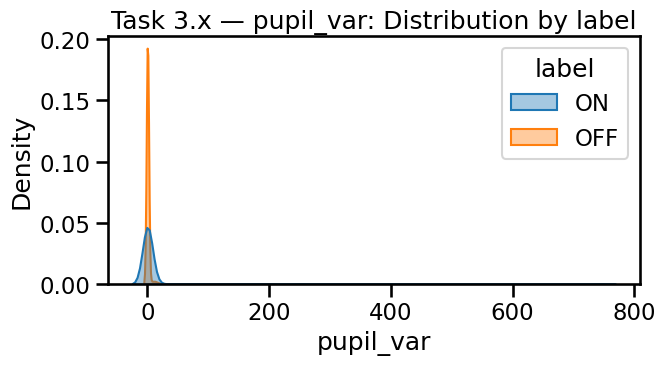

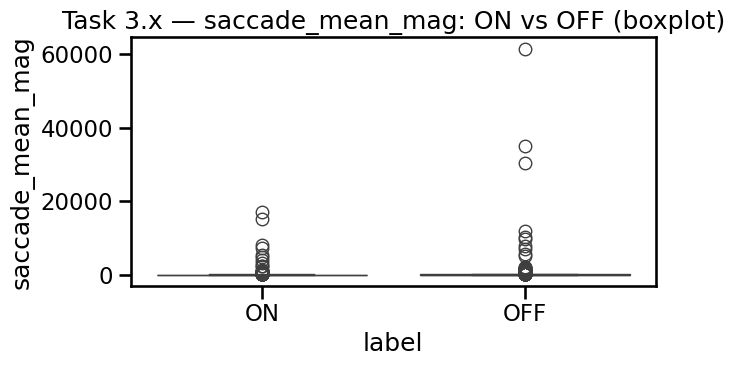

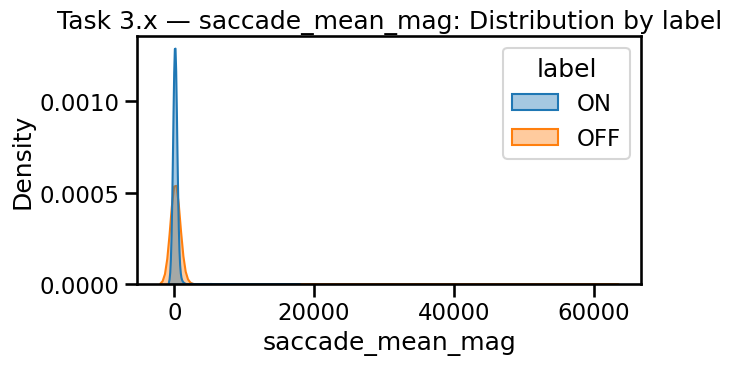

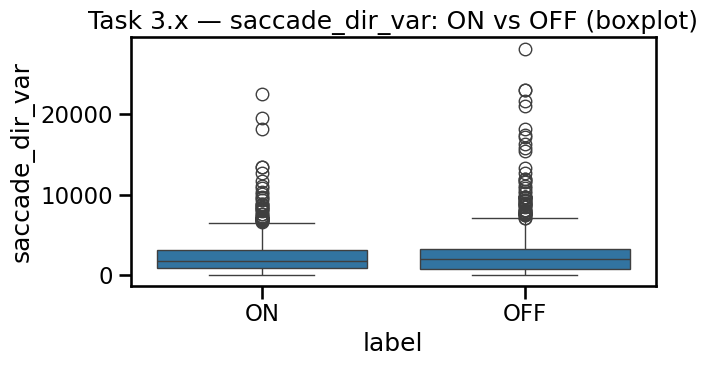

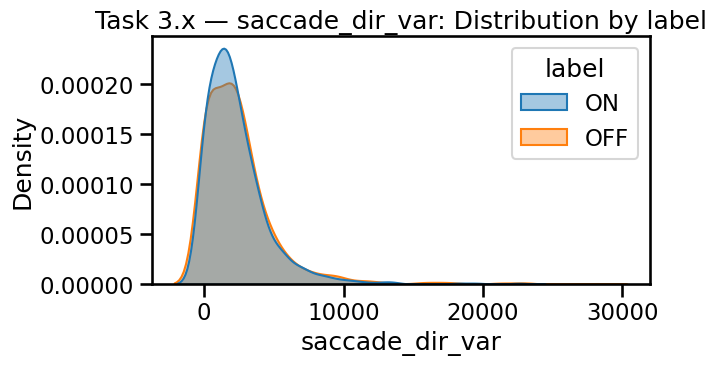

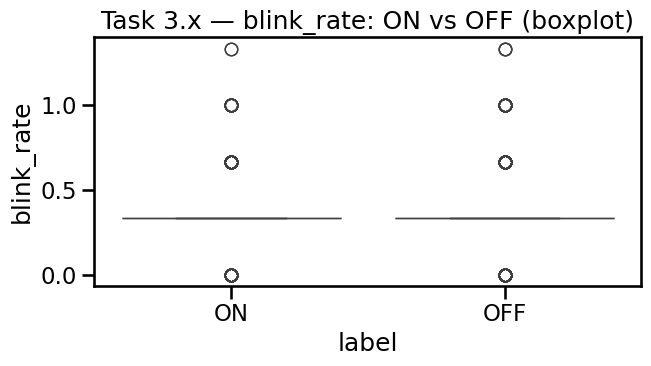

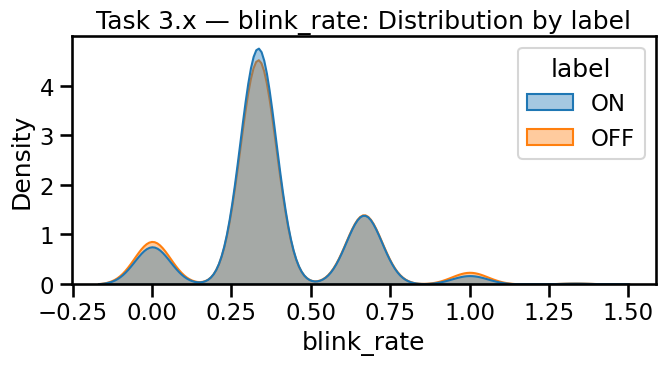

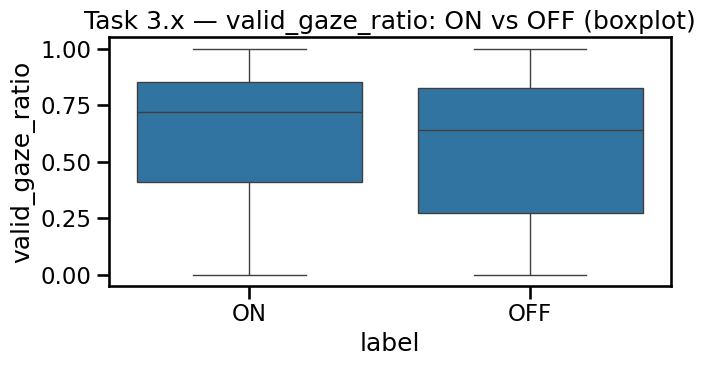

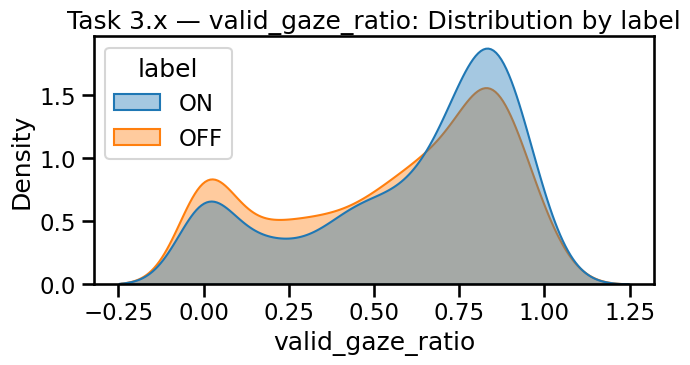

/opt/anaconda3/lib/python3.12/site-packages/scipy/stats/_axis_nan_policy.py:531: UserWarning: scipy.stats.shapiro: Input data has range zero. The results may not be accurate.
  res = hypotest_fun_out(*samples, **kwds)



=== Task 3.x: Global ON vs OFF summary ===
              feature     mean_ON    mean_OFF  p_value  effect_size                     test  n_ON  n_OFF
     valid_gaze_ratio    0.604338    0.551338 0.000634    -0.068147 Mann-Whitney (Cliff's δ)   745   1007
     saccade_mean_mag  171.636748  304.725458 0.001305     0.123648 Mann-Whitney (Cliff's δ)   666    884
       fix_efficiency   16.952558   15.474628 0.015894    -0.069725 Mann-Whitney (Cliff's δ)   651    839
            pupil_var    3.007671    0.998422 0.030670    -0.017027 Mann-Whitney (Cliff's δ)   745   1007
gaze_dispersion_total    0.293666    0.330583 0.380743     0.024098 Mann-Whitney (Cliff's δ)   652    851
      saccade_dir_var 2310.941051 2481.842849 0.604215     0.056037 Mann-Whitney (Cliff's δ)   745   1007
           pupil_mean    4.289933    4.074639 0.854515    -0.005219 Mann-Whitney (Cliff's δ)   724    956
           blink_rate    0.382103    0.384310 0.981777     0.000000 Mann-Whitney (Cliff's δ)   745   1007
  

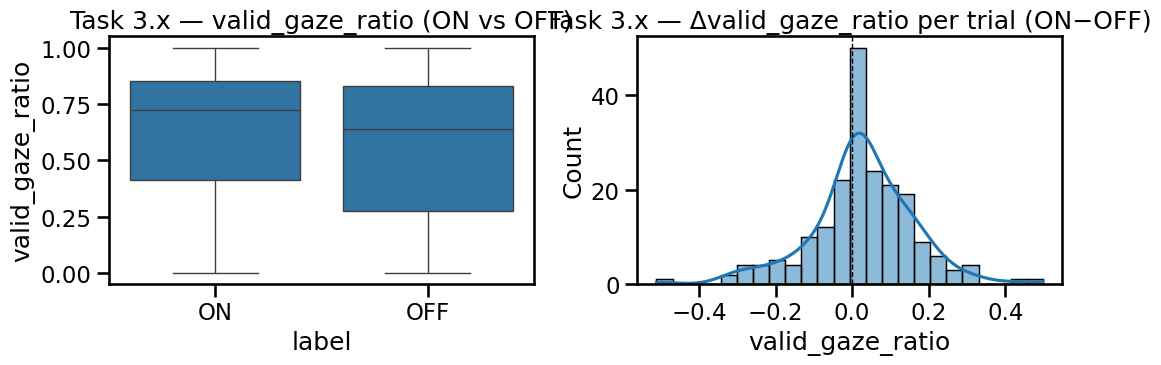

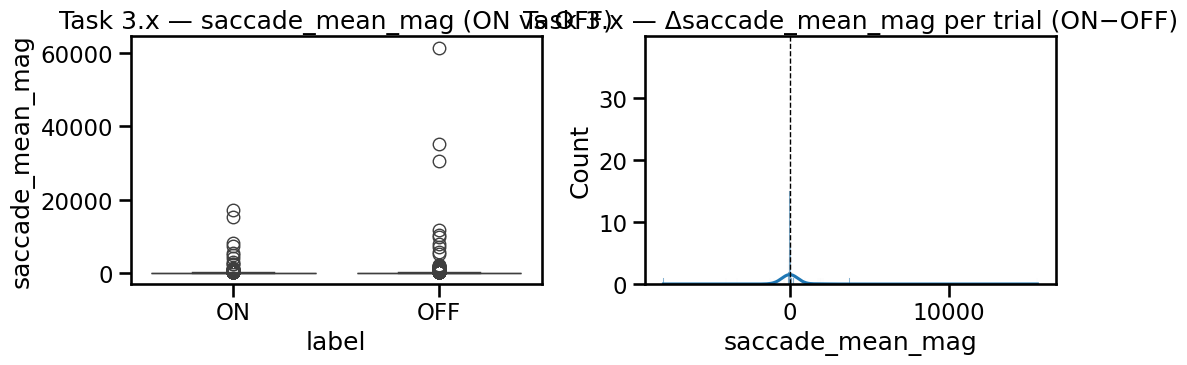

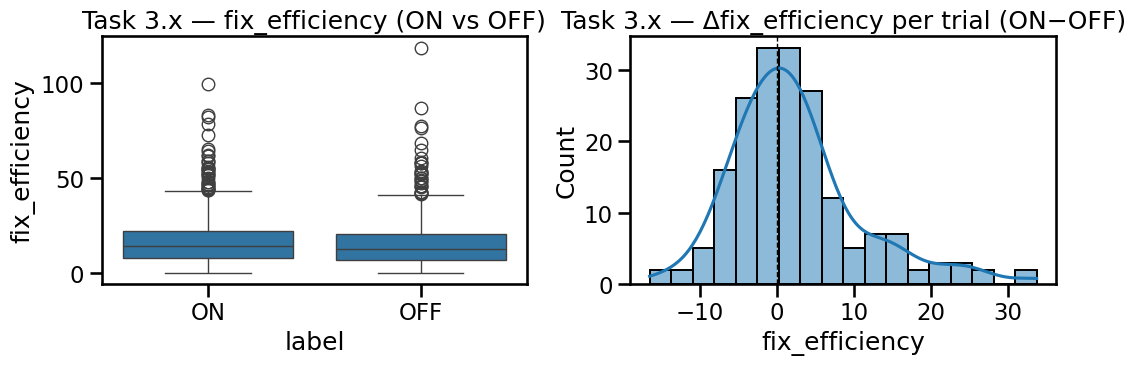

In [ ]:
sns.set_context("talk")

FEATS = [
    "fix_efficiency","fix_aoi_ratio",
    "gaze_dispersion_total",
    "pupil_mean","pupil_var",
    "saccade_mean_mag","saccade_dir_var",
    "blink_rate",
    "valid_gaze_ratio",
]

def _cohen_d(a, b):
    a, b = np.asarray(a), np.asarray(b)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    if len(a)<2 or len(b)<2: return np.nan
    na, nb = len(a), len(b)
    s = np.sqrt(((na-1)*a.var(ddof=1)+(nb-1)*b.var(ddof=1)) / (na+nb-2))
    return (a.mean()-b.mean())/s if s>0 else np.nan

def _cliffs_delta(a, b):
    a, b = np.asarray(a), np.asarray(b)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    if len(a)==0 or len(b)==0: return np.nan
    a, b = np.sort(a), np.sort(b)
    i=j=gt=lt=0; na, nb = len(a), len(b)
    while i<na and j<nb:
        if a[i]>b[j]: lt += (na-i); j+=1
        elif a[i]<b[j]: gt += (nb-j); i+=1
        else:
            ii=i; jj=j
            while ii<na and a[ii]==a[i]: ii+=1
            while jj<nb and b[jj]==b[j]: jj+=1
            i, j = ii, jj
    return (gt-lt)/(na*nb)

def _normal(x, max_n=5000, alpha=0.05):
    x = pd.Series(x).dropna()
    if len(x)<3: return False
    try:
        stat,p = shapiro(x.sample(min(max_n, len(x)), random_state=0))
        return p>alpha
    except Exception:
        return False

def analyze_on_off(windows_df: pd.DataFrame, title="Dataset"):
    df = windows_df.copy()
    df["label"] = df["label"].astype(str).str.upper().str.strip()
    df = df[df["label"].isin(["ON","OFF"])].copy()

    # Ensure identifiers exist for deltas
    for c in ["Video Name (folder)","User ID (file)","Task Id"]:
        if c not in df.columns: df[c] = "UNK"

    # --- EDA plots ---
    for f in FEATS:
        if f not in df.columns: continue
        plt.figure(figsize=(7,4))
        sns.boxplot(data=df, x="label", y=f)
        plt.title(f"{title} — {f}: ON vs OFF (boxplot)")
        plt.tight_layout(); plt.show()

        plt.figure(figsize=(7,4))
        sns.kdeplot(data=df, x=f, hue="label", common_norm=False, fill=True, alpha=0.4)
        plt.title(f"{title} — {f}: Distribution by label")
        plt.tight_layout(); plt.show()

    # --- Global tests per feature ---
    rows=[]
    for f in FEATS:
        if f not in df: continue
        on  = df.loc[df["label"]=="ON",  f].dropna()
        off = df.loc[df["label"]=="OFF", f].dropna()
        if len(on)<10 or len(off)<10:
            rows.append([f, np.nan, np.nan, np.nan, np.nan, "NA", len(on), len(off)])
            continue
        if _normal(on) and _normal(off):
            stat,p = ttest_ind(on, off, equal_var=False)
            eff = _cohen_d(on, off); test = "t-test (Cohen's d)"
        else:
            stat,p = mannwhitneyu(on, off, alternative="two-sided")
            eff = _cliffs_delta(on, off); test = "Mann-Whitney (Cliff's δ)"
        rows.append([f, on.mean(), off.mean(), p, eff, test, len(on), len(off)])

    summary = pd.DataFrame(rows, columns=["feature","mean_ON","mean_OFF","p_value","effect_size","test","n_ON","n_OFF"])
    summary = summary.sort_values(["p_value", "effect_size"], key=lambda s: (s if s.name=="p_value" else s.abs()))
    print(f"\n=== {title}: Global ON vs OFF summary ===")
    print(summary.to_string(index=False))

    # --- Participant-wise deltas (per trial) ---
    ID = ["Video Name (folder)","User ID (file)","Task Id"]
    delta_rows=[]
    for keys, grp in df.groupby(ID, dropna=False):
        on, off = grp[grp.label=="ON"], grp[grp.label=="OFF"]
        if on.empty or off.empty: continue
        d = {ID[0]:keys[0], ID[1]:keys[1], ID[2]:keys[2]}
        for f in FEATS:
            if f in grp: d[f] = on[f].mean() - off[f].mean()
        delta_rows.append(d)
    deltas = pd.DataFrame(delta_rows)
    print(f"{title}: Trials with both ON & OFF → {len(deltas)}")

    # Wilcoxon vs 0
    rows=[]
    for f in FEATS:
        if f not in deltas: continue
        x = deltas[f].dropna()
        if len(x)<10: rows.append([f, np.nan, np.nan, np.nan, len(x)]); continue
        try: stat,p = wilcoxon(x)
        except ValueError: stat,p = np.nan, np.nan
        rows.append([f, x.mean(), x.median(), p, len(x)])
    delta_summary = pd.DataFrame(rows, columns=["feature","mean_delta","median_delta","wilcoxon_p","n_trials"])
    print(f"\n=== {title}: Participant-wise Δ (ON - OFF) ===")
    print(delta_summary.sort_values("wilcoxon_p").to_string(index=False))

    # Plot top 3 features by p-value (global)
    top_feats = summary.nsmallest(3, "p_value")["feature"].tolist()
    for f in top_feats:
        fig, ax = plt.subplots(1,2, figsize=(11,4))
        sns.boxplot(data=df, x="label", y=f, ax=ax[0])
        ax[0].set_title(f"{title} — {f} (ON vs OFF)")
        if f in deltas:
            sns.histplot(deltas[f].dropna(), kde=True, ax=ax[1])
            ax[1].axvline(0, color="k", ls="--", lw=1)
            ax[1].set_title(f"{title} — Δ{f} per trial (ON−OFF)")
        plt.tight_layout(); plt.show()

    return summary, delta_summary, deltas

# ---- Run for your three window tables ----
# Assume you have: win_task1, win_task2, win_task3 (Task 1.x / 2.x / 3.x)
results = {}
for name, wdf in {
    "Task 1.x": win_task1,
    "Task 2.x": win_task2,
    "Task 3.x": win_task3,
}.items():
    print("\n" + "="*80)
    print(f"Running ON/OFF analysis → {name}")
    results[name] = analyze_on_off(wdf, title=name)

# “Do delay / direction / ease shift Δ(features)?”

In [34]:
win1 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/windows_with_animation_details1.csv")
win2 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/windows_with_animation_details2.csv")
win3 = pd.read_csv("/Users/ferolahima/Desktop/gazepoint_project/notebooks/outputs/windows_with_animation_details3.csv")


[Task 1.x] ease: built Δ rows = 201

[Task 1.x] ease: Kruskal–Wallis (top by p)
property               feature        H     p_kw  k_levels
    ease      valid_gaze_ratio 5.087152 0.024104         2
    ease        fix_efficiency 2.380146 0.122886         2
    ease       saccade_dir_var 1.897604 0.168347         2
    ease             pupil_var 1.505948 0.219758         2
    ease      saccade_mean_mag 1.356727 0.244106         2
    ease gaze_dispersion_total 0.514234 0.473312         2
    ease            blink_rate 0.390225 0.532181         2
    ease            pupil_mean 0.155976 0.692888         2
    ease         fix_aoi_ratio      NaN      NaN         2

[Task 1.x] ease: Pairwise (FDR) — top
              feature level_a  level_b  diff_mean  effect_delta    p_raw  p_fdr  n_a  n_b
       fix_efficiency Ease-in Ease-out   1.820680     -0.130277 0.123212    NaN   95   93
        fix_aoi_ratio Ease-in Ease-out   0.000000      0.000000 1.000000    NaN   95   93
gaze_dispersion_tota

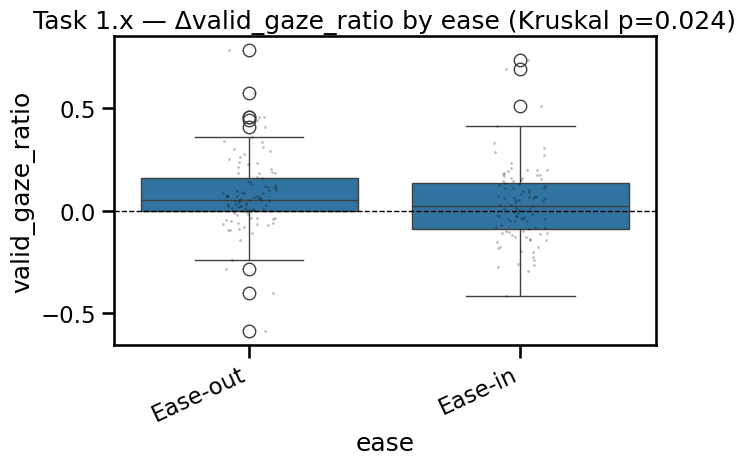


[Task 1.x] direction: built Δ rows = 201

[Task 1.x] direction: Kruskal–Wallis (top by p)
 property               feature        H     p_kw  k_levels
direction      valid_gaze_ratio 5.109056 0.023801         2
direction      saccade_mean_mag 3.293374 0.069560         2
direction gaze_dispersion_total 0.931255 0.334537         2
direction            pupil_mean 0.493250 0.482481         2
direction        fix_efficiency 0.380119 0.537540         2
direction             pupil_var 0.271885 0.602070         2
direction       saccade_dir_var 0.237630 0.625923         2
direction            blink_rate 0.001907 0.965170         2
direction         fix_aoi_ratio      NaN      NaN         2

[Task 1.x] direction: Pairwise (FDR) — top
              feature       level_a       level_b  diff_mean  effect_delta    p_raw  p_fdr  n_a  n_b
       fix_efficiency Left to Right Top to Bottom   0.479302     -0.052060 0.538424    NaN   94   94
        fix_aoi_ratio Left to Right Top to Bottom   0.000000   

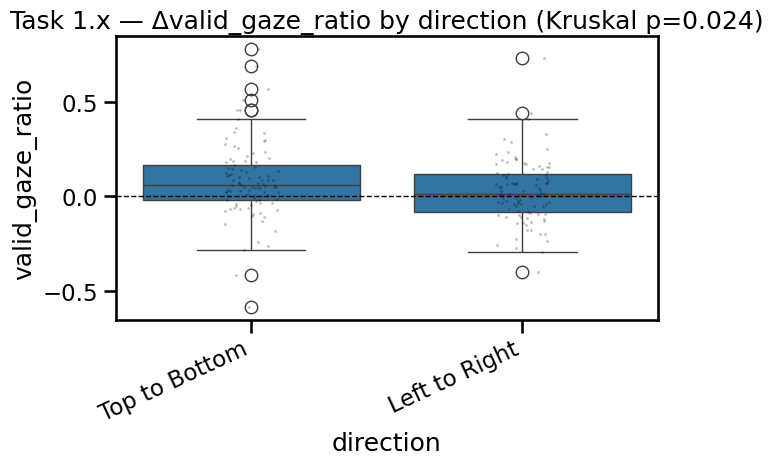


[Task 1.x] delay: built Δ rows = 201

[Task 1.x] delay: Spearman (top by p)
              feature  spearman_rho  p_spearman   n
           blink_rate      0.096062    0.174920 201
     valid_gaze_ratio     -0.060279    0.395301 201
     saccade_mean_mag      0.048519    0.508478 188
       fix_efficiency     -0.044598    0.543371 188
            pupil_var      0.042958    0.544833 201
      saccade_dir_var      0.024780    0.726951 201
           pupil_mean     -0.021244    0.766988 197
gaze_dispersion_total     -0.005391    0.941468 188
        fix_aoi_ratio           NaN         NaN 188

[Task 1.x] delay: OLS (top by p)
              feature  beta_delay   p_beta   n
            pupil_var    1.600038 0.012420 201
           blink_rate    0.047422 0.181929 201
     valid_gaze_ratio   -0.045403 0.226178 201
     saccade_mean_mag  482.829020 0.308181 188
gaze_dispersion_total    0.174787 0.436078 188
       fix_efficiency   -0.772630 0.698346 188
           pupil_mean   -0.057927 0.7854

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_7277/3446763291.py:241: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(x, y)


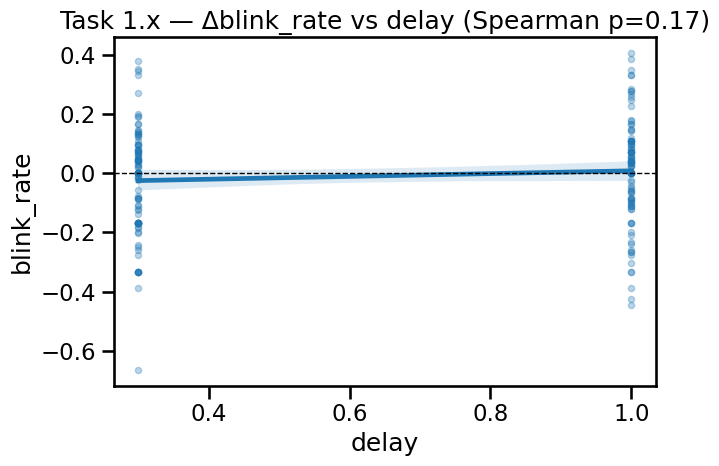


[Task 2.x] ease: built Δ rows = 199

[Task 2.x] ease: Kruskal–Wallis (top by p)
property               feature        H     p_kw  k_levels
    ease            blink_rate 1.919765 0.165883         2
    ease            pupil_mean 0.987575 0.320336         2
    ease       saccade_dir_var 0.696642 0.403914         2
    ease      saccade_mean_mag 0.379822 0.537698         2
    ease         fix_aoi_ratio 0.285249 0.593281         2
    ease gaze_dispersion_total 0.043441 0.834898         2
    ease      valid_gaze_ratio 0.026406 0.870913         2
    ease        fix_efficiency 0.021306 0.883949         2
    ease             pupil_var 0.001024 0.974466         2

[Task 2.x] ease: Pairwise (FDR) — top
              feature level_a  level_b   diff_mean  effect_delta    p_raw  p_fdr  n_a  n_b
       fix_efficiency Ease-in Ease-out    0.398894     -0.012363 0.885016    NaN   96   91
        fix_aoi_ratio Ease-in Ease-out    0.004684      0.000000 0.597585    NaN   96   91
gaze_dispersion_t

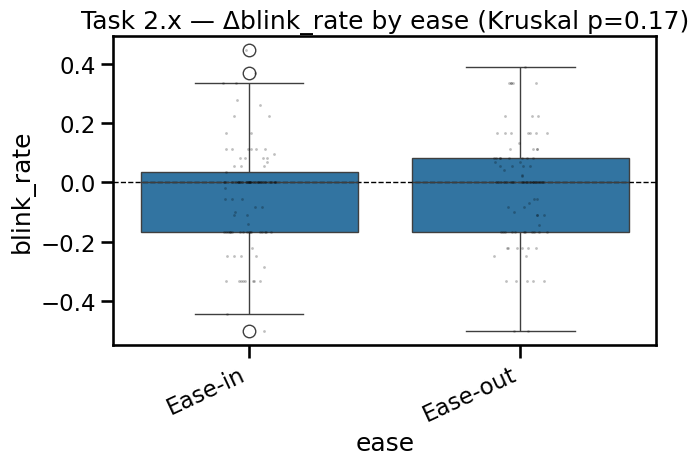


[Task 2.x] direction: built Δ rows = 199

[Task 2.x] direction: Kruskal–Wallis (top by p)
 property               feature        H     p_kw  k_levels
direction         fix_aoi_ratio 7.338339 0.025498         3
direction      valid_gaze_ratio 5.852508 0.053597         3
direction      saccade_mean_mag 3.222980 0.199590         3
direction        fix_efficiency 1.143898 0.564424         3
direction             pupil_var 0.910500 0.634289         3
direction            pupil_mean 0.491198 0.782236         3
direction       saccade_dir_var 0.384431 0.825129         3
direction gaze_dispersion_total 0.308073 0.857241         3
direction            blink_rate 0.058340 0.971251         3

[Task 2.x] direction: Pairwise (FDR) — top
         feature       level_a       level_b   diff_mean  effect_delta    p_raw    p_fdr  n_a  n_b
valid_gaze_ratio Left to Right       Pulsing    0.090142     -0.313786 0.016740 0.050219   27   72
   fix_aoi_ratio Left to Right       Pulsing    0.055166      0.000

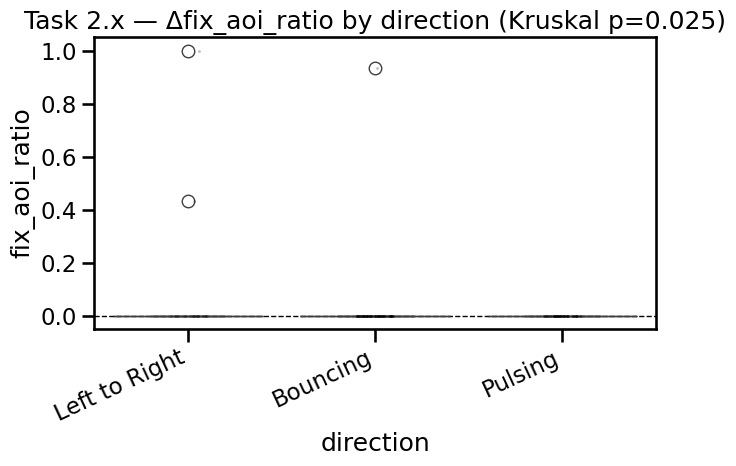


[Task 2.x] delay: built Δ rows = 199

[Task 2.x] delay: Spearman (top by p)
              feature  spearman_rho  p_spearman   n
           blink_rate      0.081635    0.251689 199
       fix_efficiency      0.078658    0.284587 187
            pupil_var      0.051262    0.472108 199
gaze_dispersion_total      0.047562    0.519149 186
        fix_aoi_ratio     -0.043245    0.556753 187
      saccade_dir_var      0.020120    0.777892 199
     saccade_mean_mag     -0.018228    0.804434 187
           pupil_mean     -0.015648    0.828552 194
     valid_gaze_ratio      0.003674    0.958925 199

[Task 2.x] delay: OLS (top by p)
              feature  beta_delay   p_beta   n
     saccade_mean_mag -371.646557 0.091370 187
           blink_rate    0.041188 0.249764 199
       fix_efficiency    2.088101 0.338967 187
      saccade_dir_var -688.626816 0.344840 199
           pupil_mean    0.204538 0.352225 194
            pupil_var    0.577182 0.598954 199
     valid_gaze_ratio    0.013695 0.7108

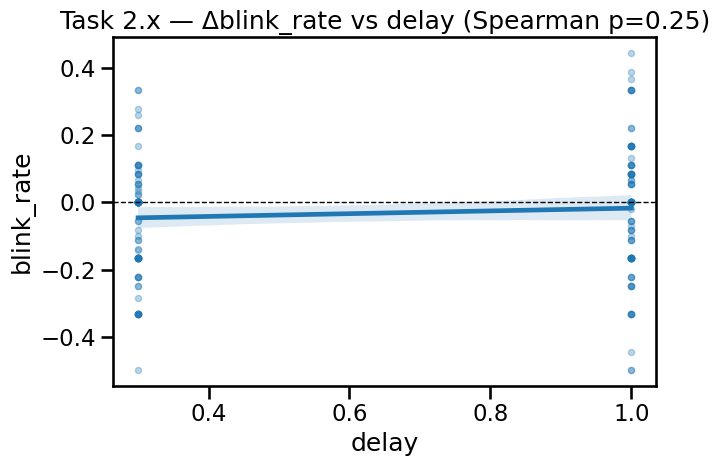


[Task 3.x] ease: built Δ rows = 202

[Task 3.x] ease: Kruskal–Wallis (top by p)
property               feature        H     p_kw  k_levels
    ease             pupil_var 6.225689 0.012591         2
    ease        fix_efficiency 3.197895 0.073733         2
    ease      saccade_mean_mag 3.119781 0.077347         2
    ease gaze_dispersion_total 0.708576 0.399917         2
    ease      valid_gaze_ratio 0.307919 0.578960         2
    ease            pupil_mean 0.273114 0.601250         2
    ease       saccade_dir_var 0.063291 0.801367         2
    ease            blink_rate 0.029444 0.863758         2
    ease         fix_aoi_ratio      NaN      NaN         2

[Task 3.x] ease: Pairwise (FDR) — top
              feature level_a  level_b   diff_mean  effect_delta    p_raw  p_fdr  n_a  n_b
       fix_efficiency Ease-in Ease-out    2.661742     -0.152281 0.073955    NaN   90   95
        fix_aoi_ratio Ease-in Ease-out    0.000000      0.000000 1.000000    NaN   90   95
gaze_dispersion_t

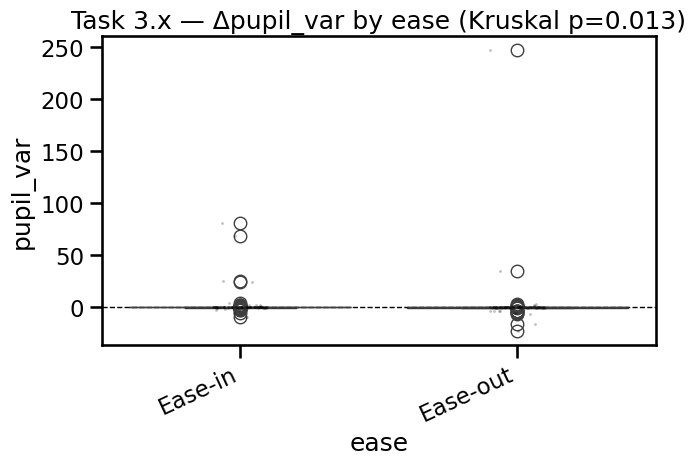


[Task 3.x] direction: built Δ rows = 202

[Task 3.x] direction: Kruskal–Wallis (top by p)
 property               feature        H     p_kw  k_levels
direction            blink_rate 2.990817 0.083738         2
direction        fix_efficiency 2.400272 0.121314         2
direction       saccade_dir_var 1.291334 0.255802         2
direction gaze_dispersion_total 1.053107 0.304793         2
direction             pupil_var 0.218120 0.640476         2
direction      valid_gaze_ratio 0.082770 0.773578         2
direction      saccade_mean_mag 0.076974 0.781441         2
direction            pupil_mean 0.000128 0.990957         2
direction         fix_aoi_ratio      NaN      NaN         2

[Task 3.x] direction: Pairwise (FDR) — top
              feature       level_a       level_b   diff_mean  effect_delta    p_raw  p_fdr  n_a  n_b
       fix_efficiency Left to Right Top to Bottom   -1.200104      0.131930 0.121645    NaN   95   90
        fix_aoi_ratio Left to Right Top to Bottom    0.000000

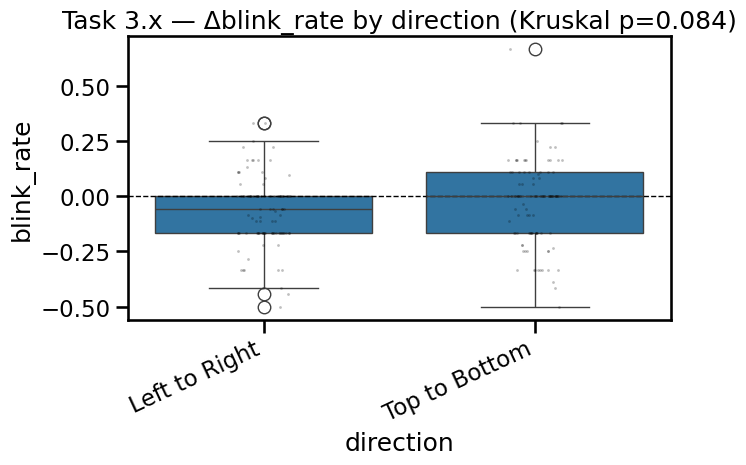


[Task 3.x] delay: built Δ rows = 202

[Task 3.x] delay: Spearman (top by p)
              feature  spearman_rho  p_spearman   n
gaze_dispersion_total     -0.178037    0.015610 184
     saccade_mean_mag     -0.106482    0.149134 185
      saccade_dir_var     -0.064191    0.364093 202
     valid_gaze_ratio     -0.063935    0.366013 202
            pupil_var     -0.045338    0.521718 202
           pupil_mean      0.034358    0.632593 196
       fix_efficiency     -0.028746    0.697706 185
           blink_rate     -0.006867    0.922727 202
        fix_aoi_ratio           NaN         NaN 185

[Task 3.x] delay: OLS (top by p)
              feature  beta_delay   p_beta   n
gaze_dispersion_total   -0.293858 0.154395 184
            pupil_var   -3.276779 0.397805 202
     saccade_mean_mag  132.834092 0.622475 185
      saccade_dir_var -191.666967 0.677404 202
     valid_gaze_ratio   -0.010882 0.746881 202
           pupil_mean    0.101813 0.781872 196
       fix_efficiency   -0.451272 0.8388

/var/folders/jh/6lrcqwz57w5_2ylmrnwyby_00000gn/T/ipykernel_7277/3446763291.py:241: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho, p = spearmanr(x, y)


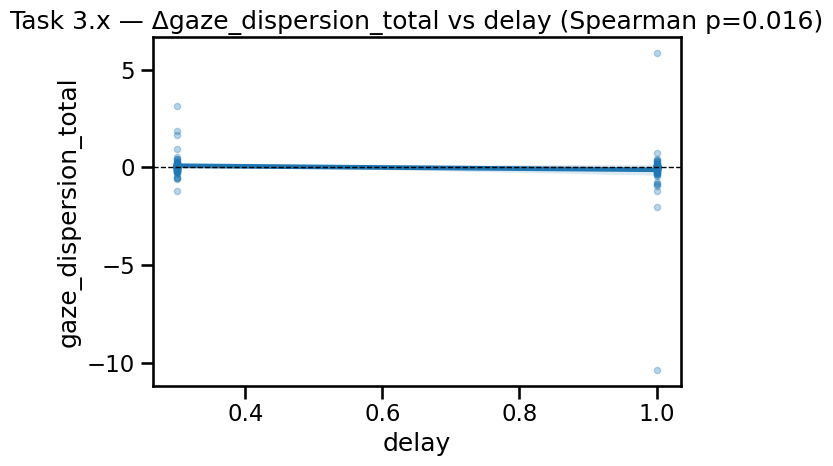

In [52]:
# =============================================
# Per-trial Δ(ON_level − OFF) by animation property
# =============================================
import numpy as np, pandas as pd
import seaborn as sns, matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu, kruskal, spearmanr, shapiro
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

sns.set_context("talk")

# ------- config -------
FEATS = [
    "fix_efficiency","fix_aoi_ratio",
    "gaze_dispersion_total",
    "pupil_mean","pupil_var",
    "saccade_mean_mag","saccade_dir_var",
    "blink_rate","valid_gaze_ratio",
]
ID_COLS = ["Video Name (folder)","User ID (file)","Task Id"]
PROP_CATS = ["ease","direction"]   # categorical properties
PROP_DELAY = "delay"               # numeric-like (we’ll parse)

MIN_ON_PER_LEVEL = 15   # skip underpowered levels
ALPHA = 0.05
PLOT = True

# ------- small helpers -------
def _normal(x, alpha=0.05, max_n=5000):
    x = pd.Series(x, dtype="float64").dropna()
    if len(x) < 3: return False
    x = x.sample(min(len(x), max_n), random_state=0)
    try:
        _, p = shapiro(x)
        return p > alpha
    except Exception:
        return False

def _cliffs_delta(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    a, b = a[~np.isnan(a)], b[~np.isnan(b)]
    if len(a) == 0 or len(b) == 0: return np.nan
    a_sorted, b_sorted = np.sort(a), np.sort(b)
    i=j=gt=lt=0
    na, nb = len(a_sorted), len(b_sorted)
    while i < na and j < nb:
        if a_sorted[i] > b_sorted[j]:
            lt += (na - i); j += 1
        elif a_sorted[i] < b_sorted[j]:
            gt += (nb - j); i += 1
        else:
            ai=i; bj=j
            while ai<na and a_sorted[ai]==a_sorted[i]: ai+=1
            while bj<nb and b_sorted[bj]==b_sorted[j]: bj+=1
            i, j = ai, bj
    return (gt - lt) / (na * nb)

def _parse_delay_series(s):
    """Turn strings like '0.3s' into float seconds; keep numeric as-is; return float series."""
    out = pd.to_numeric(s, errors="coerce")
    # try strings like '0.3s'
    need = out.isna() & s.notna()
    if need.any():
        ss = s[need].astype(str).str.strip().str.lower().str.replace("s","", regex=False)
        out.loc[need] = pd.to_numeric(ss, errors="coerce")
    return out.astype("float64")

# ------- core: build Δ per trial per property level -------
def build_deltas_by_property(win: pd.DataFrame, property_col: str, prefer_off_pre: bool = False) -> pd.DataFrame:
    """
    For each trial (Video, User, Task Id):
      - OFF baseline = mean of OFF windows (optionally prefer phase=='OFF_PRE' if available & non-empty).
      - For each ON level of `property_col` in that trial:
          Δ_f(level) = mean(ON windows with that level) - mean(OFF baseline)
    Returns one row per (trial × level) with Δ for all FEATS + the level value.
    """
    df = win.copy()
    # tidy labels & props
    df["label"] = df["label"].astype(str).str.upper().str.strip()
    if property_col not in df.columns:
        raise KeyError(f"Property '{property_col}' not found in dataframe.")
    if property_col == PROP_DELAY:
        df[property_col] = _parse_delay_series(df[property_col])
    else:
        df[property_col] = df[property_col].astype(str).str.strip()

    # keep ON/OFF rows only, and rows that have at least one feature
    df = df[df["label"].isin(["ON","OFF"])].copy()
    if "phase" in df.columns and prefer_off_pre:
        has_pre = df[df["label"]=="OFF"]["phase"].astype(str).str.upper().eq("OFF_PRE").any()

    rows = []
    for keys, grp in df.groupby(ID_COLS, dropna=False):
        g_off = grp[grp["label"]=="OFF"]
        if g_off.empty:
            continue
        # prefer OFF_PRE if requested & present
        if prefer_off_pre and "phase" in g_off.columns:
            g_pre = g_off[g_off["phase"].astype(str).str.upper().eq("OFF_PRE")]
            if not g_pre.empty:
                g_off = g_pre

        off_mean = {f: g_off[f].mean() if f in g_off else np.nan for f in FEATS}

        g_on = grp[grp["label"]=="ON"]
        if g_on.empty:
            continue

        # levels within this trial
        levels = g_on[property_col].dropna().unique().tolist()
        if len(levels) == 0:
            continue

        for lvl in levels:
            sel = g_on[g_on[property_col] == lvl]
            if sel.empty: 
                continue
            on_mean = {f: sel[f].mean() if f in sel else np.nan for f in FEATS}
            d = {ID_COLS[0]: keys[0], ID_COLS[1]: keys[1], ID_COLS[2]: keys[2],
                 property_col: lvl}
            # Δ = ON(level) − OFF(baseline)
            for f in FEATS:
                d[f] = on_mean.get(f, np.nan) - off_mean.get(f, np.nan)
            rows.append(d)

    out = pd.DataFrame(rows)
    return out

# ------- stats: categorical property (ease / direction) -------
def analyze_categorical_property(delta_df: pd.DataFrame, property_col: str, title: str):
    dd = delta_df.copy()
    dd = dd.dropna(subset=[property_col]).copy()
    # retain only levels with enough trials
    lvl_counts = dd[property_col].value_counts()
    keep_lvls = lvl_counts[lvl_counts >= MIN_ON_PER_LEVEL].index.tolist()
    dd = dd[dd[property_col].isin(keep_lvls)].copy()
    if dd.empty or len(keep_lvls) < 2:
        print(f"[{title}] {property_col}: not enough usable levels (kept {len(keep_lvls)}).")
        return None, None

    # Kruskal across levels + pairwise MW with FDR, per feature
    kw_rows, pw_rows = [], []

    for f in FEATS:
        if f not in dd.columns: 
            continue
        groups = [g[f].dropna().values for _, g in dd.groupby(property_col)]
        # need at least 2 non-empty groups
        usable = [len(g) for g in groups if len(g) > 0]
        if len(usable) < 2:
            continue

        # Kruskal–Wallis
        try:
            H, p_kw = kruskal(*groups)
        except ValueError:
            # happens if all values identical
            H, p_kw = np.nan, np.nan
        kw_rows.append({"property": property_col, "feature": f, "H": H, "p_kw": p_kw,
                        "k_levels": len(keep_lvls)})

        # Pairwise (Mann–Whitney) with FDR across pairs for this feature
        levels = list(dd[property_col].unique())
        levels.sort()
        records = []
        for i in range(len(levels)):
            for j in range(i+1, len(levels)):
                L1, L2 = levels[i], levels[j]
                x = dd.loc[dd[property_col]==L1, f].dropna().values
                y = dd.loc[dd[property_col]==L2, f].dropna().values
                if len(x) < MIN_ON_PER_LEVEL or len(y) < MIN_ON_PER_LEVEL: 
                    continue
                try:
                    stat, p = mannwhitneyu(x, y, alternative="two-sided")
                except ValueError:
                    p = np.nan
                eff = _cliffs_delta(x, y)
                records.append({"property": property_col, "feature": f,
                                "level_a": L1, "level_b": L2,
                                "n_a": len(x), "n_b": len(y),
                                "diff_mean": float(np.nanmean(x) - np.nanmean(y)),
                                "p_raw": p, "effect_delta": eff})
        if records:
            dfp = pd.DataFrame(records)
            if dfp["p_raw"].notna().sum() >= 2:
                rej, p_adj, _, _ = multipletests(dfp["p_raw"].fillna(1.0), method="fdr_bh")
                dfp["p_fdr"] = p_adj
                dfp["sig"] = rej
            else:
                dfp["p_fdr"] = np.nan; dfp["sig"] = False
            pw_rows.append(dfp)

    kw_df = pd.DataFrame(kw_rows)
    pw_df = pd.concat(pw_rows, ignore_index=True) if pw_rows else pd.DataFrame()

    # Quick print
    if not kw_df.empty:
        top_kw = kw_df.sort_values("p_kw").head(10)
        print(f"\n[{title}] {property_col}: Kruskal–Wallis (top by p)")
        print(top_kw.to_string(index=False))
    if not pw_df.empty:
        top_pw = pw_df.sort_values("p_fdr").head(10)
        print(f"\n[{title}] {property_col}: Pairwise (FDR) — top")
        print(top_pw[["feature","level_a","level_b","diff_mean","effect_delta","p_raw","p_fdr","n_a","n_b"]]
              .to_string(index=False))

    # Optional plot: per-level box for the best feature
    if PLOT and not kw_df.empty:
        best_feat = kw_df.loc[kw_df["p_kw"].idxmin(), "feature"]
        plt.figure(figsize=(7,5))
        sns.boxplot(data=dd, x=property_col, y=best_feat)
        sns.stripplot(data=dd, x=property_col, y=best_feat, color="k", alpha=0.25, size=2)
        plt.axhline(0, ls="--", lw=1, c="k")
        plt.title(f"{title} — Δ{best_feat} by {property_col} (Kruskal p={kw_df['p_kw'].min():.2g})")
        plt.xticks(rotation=25, ha="right")
        plt.tight_layout(); plt.show()

    return kw_df, pw_df

# ------- stats: numeric delay (correlation + OLS) -------
def analyze_delay_property(delta_df: pd.DataFrame, title: str):
    if PROP_DELAY not in delta_df.columns:
        print(f"[{title}] delay column not found.")
        return None, None
    dd = delta_df.dropna(subset=[PROP_DELAY]).copy()
    if dd.empty:
        print(f"[{title}] No usable delay values.")
        return None, None

    corr_rows, ols_rows = [], []
    for f in FEATS:
        if f not in dd.columns: 
            continue
        x = dd[PROP_DELAY].astype(float).values
        y = dd[f].astype(float).values
        mask = np.isfinite(x) & np.isfinite(y)
        x, y = x[mask], y[mask]
        if len(x) < 30:
            continue
        # Spearman correlation (robust to non-normal)
        rho, p = spearmanr(x, y)
        corr_rows.append({"feature": f, "spearman_rho": rho, "p_spearman": p, "n": len(x)})

        # OLS (simple) with robust SE
        X = sm.add_constant(x)
        model = sm.OLS(y, X, missing="drop").fit(cov_type="HC3")
        b1 = model.params[1]; p_b1 = model.pvalues[1]
        ols_rows.append({"feature": f, "beta_delay": b1, "p_beta": p_b1, "n": len(x)})

    corr_df = pd.DataFrame(corr_rows)
    ols_df = pd.DataFrame(ols_rows)

    if not corr_df.empty:
        top = corr_df.sort_values("p_spearman").head(10)
        print(f"\n[{title}] delay: Spearman (top by p)")
        print(top.to_string(index=False))
    if not ols_df.empty:
        top = ols_df.sort_values("p_beta").head(10)
        print(f"\n[{title}] delay: OLS (top by p)")
        print(top.to_string(index=False))

    # Optional plot: best feature vs delay
    if PLOT and not corr_df.empty:
        best_feat = corr_df.loc[corr_df["p_spearman"].idxmin(), "feature"]
        plt.figure(figsize=(7,5))
        sns.regplot(data=dd, x=PROP_DELAY, y=best_feat, scatter_kws=dict(alpha=0.3, s=20))
        plt.axhline(0, ls="--", lw=1, c="k")
        plt.title(f"{title} — Δ{best_feat} vs delay (Spearman p={corr_df['p_spearman'].min():.2g})")
        plt.tight_layout(); plt.show()

    return corr_df, ols_df

# ------- master runner per dataset -------
def run_property_vs_off(win_df: pd.DataFrame, title: str, prefer_off_pre: bool = False):
    results = {}

    # Categorical properties: build Δ table then analyze
    for prop in [p for p in PROP_CATS if p in win_df.columns]:
        deltas_prop = build_deltas_by_property(win_df, prop, prefer_off_pre=prefer_off_pre)
        print(f"\n[{title}] {prop}: built Δ rows = {len(deltas_prop)}")
        if deltas_prop.empty:
            continue
        kw_df, pw_df = analyze_categorical_property(deltas_prop, prop, title)
        results[f"{prop}_deltas"] = deltas_prop
        results[f"{prop}_kw"] = kw_df
        results[f"{prop}_pairwise"] = pw_df

    # Numeric delay (if present / parseable)
    if PROP_DELAY in win_df.columns:
        deltas_delay = build_deltas_by_property(win_df, PROP_DELAY, prefer_off_pre=prefer_off_pre)
        print(f"\n[{title}] delay: built Δ rows = {len(deltas_delay)}")
        if not deltas_delay.empty:
            corr_df, ols_df = analyze_delay_property(deltas_delay, title)
            results["delay_deltas"] = deltas_delay
            results["delay_corr"] = corr_df
            results["delay_ols"] = ols_df

    return results

# =========================
# HOW TO RUN (three datasets)
# =========================
# Example variables you already have:
#   win_task1, win_task2, win_task3
# Each is a windows table (one animation family), with FEATS + 'label' + properties.

res1 = run_property_vs_off(win1, "Task 1.x", prefer_off_pre=True)
res2 = run_property_vs_off(win2, "Task 2.x", prefer_off_pre=True)
res3 = run_property_vs_off(win3, "Task 3.x", prefer_off_pre=True)

# Optionally save key outputs
# if "ease_deltas" in res1:  res1["ease_deltas"].to_csv("outputs/task1_ease_deltas.csv", index=False)
# if "direction_pairwise" in res1: res1["direction_pairwise"].to_csv("outputs/task1_direction_pairwise.csv", index=False)